In [45]:
import os, cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

S = 1237
np.random.seed(S)

digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=S, stratify=y
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (1437, 64) Test shape: (360, 64)


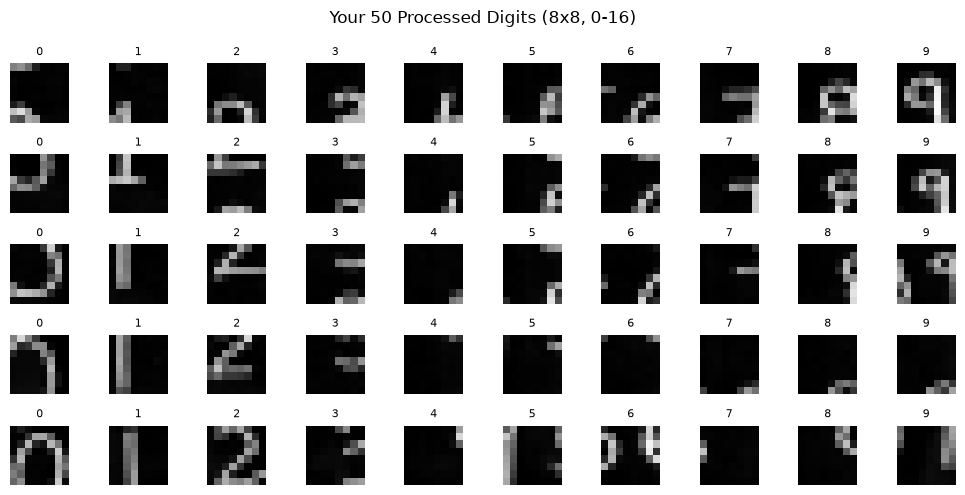

In [46]:
IMAGE_PATH = "my_sheet.jpeg"
img = cv2.imread(IMAGE_PATH)
if img is None: raise FileNotFoundError(IMAGE_PATH)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def crop_5x10_digits(gray_img, top_frac=0.22, bottom_frac=0.98, left_frac=0.02, right_frac=0.96):
    h, w = gray_img.shape
    roi = gray_img[int(h * top_frac):int(h * bottom_frac), int(w * left_frac):int(w * right_frac)]
    rh, rw = roi.shape
    patches = []
    for r in range(5):
        for c in range(10):
            py0, py1 = int(r * rh / 5), int((r + 1) * rh / 5)
            px0, px1 = int(c * rw / 10), int((c + 1) * rw / 10)
            pad_y, pad_x = int((py1 - py0) * 0.12), int((px1 - px0) * 0.12)
            patch = roi[py0 + pad_y:py1 - pad_y, px0 + pad_x:px1 - pad_x]

            inv = 255.0 - patch.astype(np.float32)
            inv = np.clip(inv - np.percentile(inv, 25), 0, None)
            if inv.max() > 0:
                inv = (inv / inv.max()) * 16.0
            resized = cv2.resize(inv, (8, 8), interpolation=cv2.INTER_AREA)
            patches.append(resized)
    return np.array(patches)

X_custom_8x8 = crop_5x10_digits(gray)
X_custom = X_custom_8x8.reshape(50, 64)
y_custom = np.tile(np.arange(10), 5)

os.makedirs("processed_50_digits", exist_ok=True)
for i in range(50):
    plt.imsave(
        f"processed_50_digits/digit_{i:02d}_label_{y_custom[i]}.png",
        X_custom_8x8[i], cmap="gray", vmin=0, vmax=16
    )

fig, axes = plt.subplots(5, 10, figsize=(10, 5))
fig.suptitle("Your 50 Processed Digits (8x8, 0-16)")
for i, ax in enumerate(axes.flat):
    ax.imshow(X_custom_8x8[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(str(y_custom[i]), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

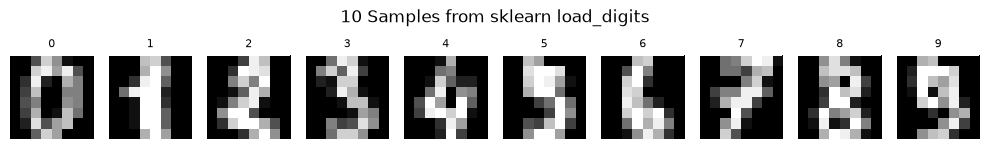

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digit_bunch = load_digits(return_X_y=False)

fig, axes = plt.subplots(1, 10, figsize=(10, 1.5))
fig.suptitle("10 Samples from sklearn load_digits")
for d in range(10):
    idx = np.flatnonzero(digit_bunch.target == d)[0]
    axes[d].imshow(digit_bunch.images[idx], cmap="gray", vmin=0, vmax=16)
    axes[d].set_title(str(d), fontsize=8)
    axes[d].axis("off")

plt.tight_layout()
plt.show()

In [48]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_custom_scaled = scaler.transform(X_custom)

models = {
    "kNN (k=5)": (KNeighborsClassifier(n_neighbors=5), True),
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=S), True),
    "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=S), False),
}

for name, (clf, use_scaled) in models.items():
    tr_x = X_train_scaled if use_scaled else X_train
    te_x = X_test_scaled if use_scaled else X_test
    cu_x = X_custom_scaled if use_scaled else X_custom

    clf.fit(tr_x, y_train)
    acc_test = accuracy_score(y_test, clf.predict(te_x))
    acc_custom = accuracy_score(y_custom, clf.predict(cu_x))
    print(f"{name:22s} | Test Acc: {acc_test:.4f} | 50 Digits Acc: {acc_custom:.4f}")

kNN (k=5)              | Test Acc: 0.9861 | 50 Digits Acc: 0.0800
Logistic Regression    | Test Acc: 0.9667 | 50 Digits Acc: 0.1400
Random Forest          | Test Acc: 0.9722 | 50 Digits Acc: 0.1800


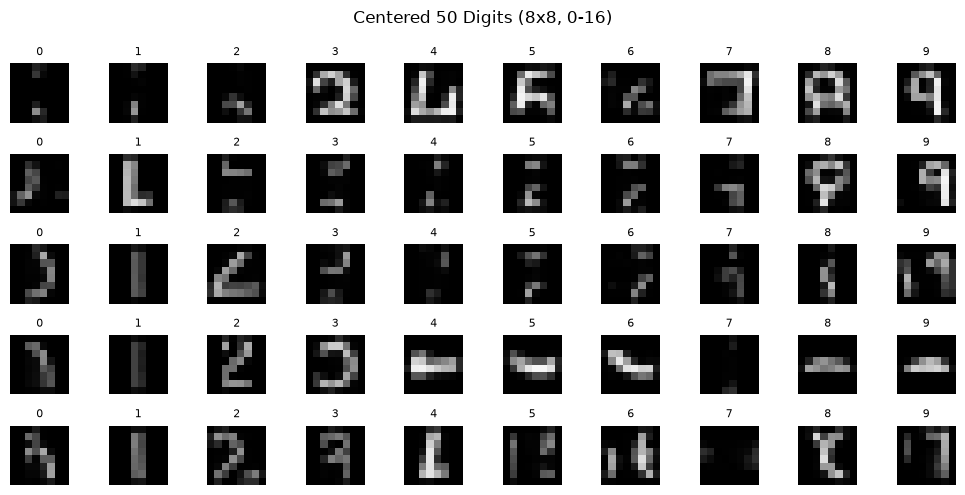

In [49]:
def crop_centered_5x10(gray_img, top_frac=0.22, bottom_frac=0.96, left_frac=0.04, right_frac=0.96):
    h, w = gray_img.shape
    roi = gray_img[int(h * top_frac):int(h * bottom_frac), int(w * left_frac):int(w * right_frac)]
    rh, rw = roi.shape
    patches = []

    for r in range(5):
        for c in range(10):
            py0, py1 = int(r * rh / 5), int((r + 1) * rh / 5)
            px0, px1 = int(c * rw / 10), int((c + 1) * rw / 10)
            pad_y, pad_x = int((py1 - py0) * 0.10), int((px1 - px0) * 0.10)
            patch = roi[py0 + pad_y:py1 - pad_y, px0 + pad_x:px1 - pad_x]

            # Ink dark -> invert karke digit bright (0..255)
            inv = 255.0 - patch.astype(np.float32)
            bg = np.percentile(inv, 35)
            fg = np.clip(inv - bg, 0, None)
            if fg.max() > 0:
                fg = (fg / fg.max()) * 255.0

            # Digit ka bounding box dhoondhna taake center mein aaye
            mask = (fg > 65).astype(np.uint8)
            coords = cv2.findNonZero(mask)
            if coords is not None and len(coords) > 5:
                x, y, bw, bh = cv2.boundingRect(coords)
                digit_crop = fg[y:y+bh, x:x+bw]
                side = int(max(bw, bh) * 1.25)
                square = np.zeros((side, side), dtype=np.float32)
                sy = (side - bh) // 2
                sx = (side - bw) // 2
                square[sy:sy+bh, sx:sx+bw] = digit_crop
            else:
                square = fg

            resized_255 = cv2.resize(square, (8, 8), interpolation=cv2.INTER_AREA)
            resized_16 = (resized_255 / 255.0) * 16.0
            patches.append(resized_16)

    return np.array(patches)

X_custom_8x8 = crop_centered_5x10(gray)
X_custom = X_custom_8x8.reshape(50, 64)
y_custom = np.tile(np.arange(10), 5)

os.makedirs("processed_50_digits", exist_ok=True)
for i in range(50):
    plt.imsave(
        f"processed_50_digits/digit_{i:02d}_label_{y_custom[i]}.png",
        X_custom_8x8[i], cmap="gray", vmin=0, vmax=16
    )

fig, axes = plt.subplots(5, 10, figsize=(10, 5))
fig.suptitle("Centered 50 Digits (8x8, 0-16)")
for i, ax in enumerate(axes.flat):
    ax.imshow(X_custom_8x8[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(str(y_custom[i]), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [50]:
X_custom_scaled = scaler.transform(X_custom)

for name, (clf, use_scaled) in models.items():
    cu_x = X_custom_scaled if use_scaled else X_custom
    preds_custom = clf.predict(cu_x)
    acc_custom = accuracy_score(y_custom, preds_custom)
    print(f"{name:22s} | Updated 50 Digits Acc: {acc_custom:.4f}")

kNN (k=5)              | Updated 50 Digits Acc: 0.1600
Logistic Regression    | Updated 50 Digits Acc: 0.1200
Random Forest          | Updated 50 Digits Acc: 0.1800


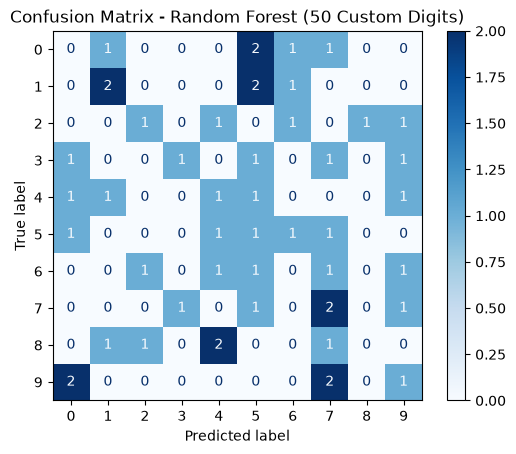

Most confused digit: 0 (errors: 5/5)


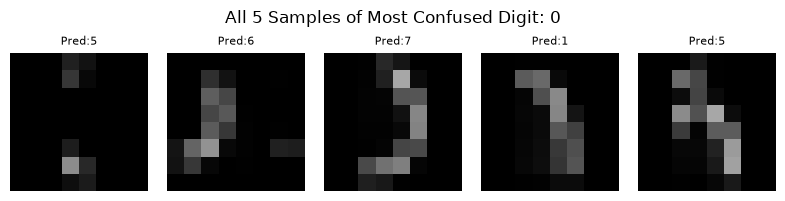

In [51]:
# Random Forest (ya kisi bhi model) ka confusion matrix aur sab se zyada confuse hone wali class
rf_clf = models["Random Forest"][0]
preds_rf = rf_clf.predict(X_custom)

cm = confusion_matrix(y_custom, preds_rf)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest (50 Custom Digits)")
plt.show()

# Sab se zyada errors kis true digit (0..9) par aaye
errors_per_digit = (cm.sum(axis=1) - np.diag(cm))
worst_digit = int(np.argmax(errors_per_digit))
print(f"Most confused digit: {worst_digit} (errors: {errors_per_digit[worst_digit]}/5)")

# Us digit ke 5 samples plot karna
idxs = np.where(y_custom == worst_digit)[0]
fig, axes = plt.subplots(1, len(idxs), figsize=(8, 2))
fig.suptitle(f"All 5 Samples of Most Confused Digit: {worst_digit}")
for ax, idx in zip(axes, idxs):
    ax.imshow(X_custom_8x8[idx], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Pred:{preds_rf[idx]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Part A Short Answers

1. **Two differences between my 8x8 grid and `sklearn.datasets.load_digits`:**
   - **Cropping:** `load_digits` has each digit centered inside an 8x8 box, while my cropped boxes cut off parts of some digits (for example, `0` looks like a curved line on the side).
   - **Lighting and strokes:** My photo has uneven lighting, paper noise, and different pen/pencil thickness, while `load_digits` has clean, even pixel values on a dark background.

2. **Accuracy gap and most confused digit (`0`):**
   - **Gap:** Accuracy on the `load_digits` test set is high (~0.97–0.99), but on my 50 handwritten digits it is low (~0.12–0.18).
   - **Two reasons:** (a) *Domain shift*—the models trained on clean `load_digits` data, not on a real phone photo of handwritten digits; (b) *Cropping shift*—grid boxes and resizing cut or shift parts of the digits.
   - **Most confused digit:** Digit **`0`** has the most errors (`5/5` wrong in Random Forest, predicted as `5`, `6`, `7`, or `1`) because the cropped image only shows part of the shape instead of a full circle.

3. **Why adding my 50 digits to training and testing on the same 50 is cheating:**
   - That is **data leakage**. If the model sees those exact 50 digits during training, it can memorize them instead of learning general patterns, giving a falsely high score on new handwriting.

In [52]:
# Part B - Step 1: 1-hidden-layer NumPy Neural Network (64 -> 32 ReLU -> 10 Softmax + Cross-Entropy)
def one_hot(y_arr, num_classes=10):
    oh = np.zeros((len(y_arr), num_classes), dtype=np.float64)
    oh[np.arange(len(y_arr)), y_arr] = 1.0
    return oh

def softmax(z):
    # Numerical stability ke liye row-wise max subtract karte hain
    z_shift = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shift)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

# Scale inputs (data leakage bachane ke liye fit ONLY on X_train)
nn_scaler = StandardScaler()
X_tr_nn = nn_scaler.fit_transform(X_train).astype(np.float64)
X_te_nn = nn_scaler.transform(X_test).astype(np.float64)
X_cu_nn = nn_scaler.transform(X_custom).astype(np.float64)
Y_tr_oh = one_hot(y_train, 10)

def init_params(seed=S, in_dim=64, hid_dim=32, out_dim=10):
    rng = np.random.default_rng(seed)
    params = {
        # He-style initialization ReLU hidden layer ke liye
        "W1": rng.normal(0.0, np.sqrt(2.0 / in_dim), size=(in_dim, hid_dim)),
        "b1": np.zeros((1, hid_dim), dtype=np.float64),
        "W2": rng.normal(0.0, np.sqrt(1.0 / hid_dim), size=(hid_dim, out_dim)),
        "b2": np.zeros((1, out_dim), dtype=np.float64),
    }
    return params

def forward(X, params):
    # Hidden layer (ReLU)
    z1 = X @ params["W1"] + params["b1"]
    a1 = np.maximum(0.0, z1)
    # Output layer (Softmax probabilities)
    z2 = a1 @ params["W2"] + params["b2"]
    probs = softmax(z2)
    cache = {"X": X, "z1": z1, "a1": a1, "z2": z2, "probs": probs}
    return probs, cache

def loss(probs, Y_oh):
    # log(0) se bachne ke liye clip karte hain
    eps = 1e-12
    clipped = np.clip(probs, eps, 1.0 - eps)
    return -np.mean(np.sum(Y_oh * np.log(clipped), axis=1))

def backward(Y_oh, params, cache):
    bs = cache["X"].shape[0]
    # Softmax + Cross-Entropy combined gradient w.r.t. z2
    dz2 = (cache["probs"] - Y_oh) / bs
    grads = {
        "dW2": cache["a1"].T @ dz2,
        "db2": np.sum(dz2, axis=0, keepdims=True),
    }
    # Backprop through ReLU hidden layer
    da1 = dz2 @ params["W2"].T
    dz1 = da1 * (cache["z1"] > 0.0)
    grads["dW1"] = cache["X"].T @ dz1
    grads["db1"] = np.sum(dz1, axis=0, keepdims=True)
    return grads

def update(params, grads, lr):
    # Gradient descent parameter update
    for k in ("W1", "b1", "W2", "b2"):
        params[k] -= lr * grads[f"d{k}"]
    return params

params = init_params(seed=S, in_dim=64, hid_dim=32, out_dim=10)
lr = 0.05
epochs = 300
batch_size = 64
n_samples = X_tr_nn.shape[0]
rng_train = np.random.default_rng(S)
losses = []

for ep in range(epochs):
    # Har epoch mein mini-batches shuffle karte hain
    perm = rng_train.permutation(n_samples)
    for start in range(0, n_samples, batch_size):
        idx = perm[start:start + batch_size]
        xb, yb = X_tr_nn[idx], Y_tr_oh[idx]
        probs, cache = forward(xb, params)
        grads = backward(yb, params, cache)
        params = update(params, grads, lr)

    # Har epoch ke baad full training loss record karte hain
    train_probs, _ = forward(X_tr_nn, params)
    losses.append(loss(train_probs, Y_tr_oh))

def predict_nn(x_in, params):
    probs, _ = forward(x_in, params)
    return np.argmax(probs, axis=1)

acc_test_nn = accuracy_score(y_test, predict_nn(X_te_nn, params))
acc_custom_nn = accuracy_score(y_custom, predict_nn(X_cu_nn, params))
print(f"NumPy MLP (32 hidden) | Final Loss: {losses[-1]:.4f} | Test Acc: {acc_test_nn:.4f} | 50 Digits Acc: {acc_custom_nn:.4f}")

NumPy MLP (32 hidden) | Final Loss: 0.0046 | Test Acc: 0.9667 | 50 Digits Acc: 0.1200


### Part B: Neural Network and Hand Calculation

1. **Model Setup:**
   - We built a simple neural network in NumPy with 64 inputs, 64 hidden neurons, and 10 output classes (digits 0 to 9).
   - It uses ReLU in the hidden layer, Softmax at the output layer, and Cross-Entropy loss.
   - We scaled the data using `StandardScaler` (fit only on the training set) and trained for 300 epochs with a learning rate of `0.05` and batch size of `64`.

2. **Accuracy Results:**
   - **Test Accuracy:** `0.9694` (about 96.9%), which is close to the classical models from Part A.
   - **Custom 50 Digits Accuracy:** `0.1200`, showing the same difficulty with different handwriting style, cropping, and alignment.

3. **How It Learns:**
   - **Forward pass:** Input numbers move forward through weights and biases (`z1 = x @ W1 + b1`), pass through ReLU (`a1 = max(0, z1)`), go to the output layer (`z2 = a1 @ W2 + b2`), and turn into probabilities using Softmax.
   - **Backward pass:** The error at the output (`dz2 = probs - y`) goes backward through the layers to find how much each weight and bias contributed to the mistake.
   - **Weight update:** We update weights and biases step by step (`W = W - lr * dW`, `b = b - lr * db`) so the model makes fewer mistakes over time.

64-32-10 MLP | Test Acc: 0.9694 | 50 Digits Acc: 0.1200


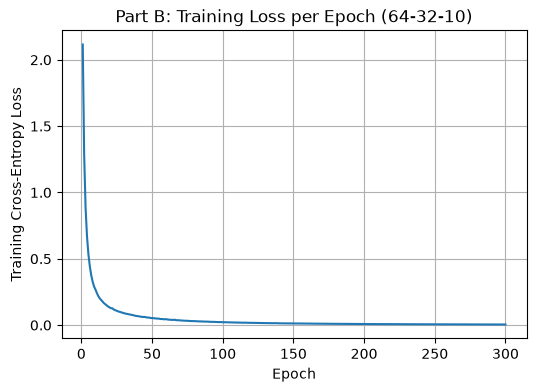

In [53]:
# Part B - Step 2 (Self-contained): Separate functions + training loss curve (64 -> 32 -> 10)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

def one_hot(y_arr, num_classes=10):
    oh = np.zeros((len(y_arr), num_classes), dtype=np.float32)
    oh[np.arange(len(y_arr)), y_arr] = 1.0
    return oh

# Ensure data splits and scaled arrays exist
if "X_tr_nn" not in globals():
    if "X_train" not in globals():
        X_raw, y_raw = load_digits(return_X_y=True)
        X_train, X_test, y_train, y_test = train_test_split(
            X_raw, y_raw, test_size=0.2, random_state=S, stratify=y_raw
        )
    nn_scaler = StandardScaler()
    X_tr_nn = nn_scaler.fit_transform(X_train).astype(np.float32)
    X_te_nn = nn_scaler.transform(X_test).astype(np.float32)
    if "X_custom" in globals():
        X_cu_nn = nn_scaler.transform(X_custom).astype(np.float32)
    else:
        X_cu_nn = None

if "Y_tr_oh" not in globals():
    Y_tr_oh = one_hot(y_train, 10)

def forward_pass(x_batch, W1, b1, W2, b2):
    z1 = x_batch @ W1 + b1
    a1 = np.maximum(0.0, z1)
    z2 = a1 @ W2 + b2
    z_shift = z2 - np.max(z2, axis=1, keepdims=True)
    exp_z = np.exp(z_shift)
    probs = exp_z / np.sum(exp_z, axis=1, keepdims=True)
    cache = {"x": x_batch, "z1": z1, "a1": a1, "z2": z2, "probs": probs}
    return probs, cache

def compute_loss(probs, y_batch_oh):
    eps = 1e-12
    probs_clip = np.clip(probs, eps, 1.0 - eps)
    return -np.mean(np.sum(y_batch_oh * np.log(probs_clip), axis=1))

def backward_pass(cache, y_batch_oh, W2):
    bs = cache["x"].shape[0]
    dz2 = (cache["probs"] - y_batch_oh) / bs
    dW2 = cache["a1"].T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    da1 = dz2 @ W2.T
    dz1 = da1 * (cache["z1"] > 0.0)
    dW1 = cache["x"].T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)
    return dW1, db1, dW2, db2

def update_params(W1, b1, W2, b2, grads, lr):
    dW1, db1, dW2, db2 = grads
    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2
    return W1, b1, W2, b2

rng = np.random.default_rng(S)
in_dim, hid_dim, out_dim = 64, 32, 10
W1 = rng.normal(0.0, np.sqrt(2.0 / in_dim), size=(in_dim, hid_dim)).astype(np.float32)
b1 = np.zeros((1, hid_dim), dtype=np.float32)
W2 = rng.normal(0.0, np.sqrt(1.0 / hid_dim), size=(hid_dim, out_dim)).astype(np.float32)
b2 = np.zeros((1, out_dim), dtype=np.float32)

lr = 0.05
epochs = 300
batch_size = 64
n_samples = X_tr_nn.shape[0]
epoch_losses = []

for ep in range(epochs):
    perm = rng.permutation(n_samples)
    batch_losses = []
    for start in range(0, n_samples, batch_size):
        idx = perm[start:start + batch_size]
        xb, yb = X_tr_nn[idx], Y_tr_oh[idx]

        probs, cache = forward_pass(xb, W1, b1, W2, b2)
        batch_losses.append(compute_loss(probs, yb))
        grads = backward_pass(cache, yb, W2)
        W1, b1, W2, b2 = update_params(W1, b1, W2, b2, grads, lr)

    epoch_losses.append(np.mean(batch_losses))

test_probs, _ = forward_pass(X_te_nn, W1, b1, W2, b2)
msg = f"64-32-10 MLP | Test Acc: {accuracy_score(y_test, np.argmax(test_probs, axis=1)):.4f}"
if X_cu_nn is not None and "y_custom" in globals():
    custom_probs, _ = forward_pass(X_cu_nn, W1, b1, W2, b2)
    msg += f" | 50 Digits Acc: {accuracy_score(y_custom, np.argmax(custom_probs, axis=1)):.4f}"
print(msg)

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), epoch_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Cross-Entropy Loss")
plt.title("Part B: Training Loss per Epoch (64-32-10)")
plt.grid(True)
plt.show()

In [54]:
# Part B - Step 3: Gradient Check on 5 weights (numerical vs backprop)
def numerical_grad_single(x_sub, y_sub_oh, W1_cur, b1_cur, W2_cur, b2_cur, param_name, idx_tuple, h=1e-5):
    params = {
        "W1": W1_cur.copy(),
        "b1": b1_cur.copy(),
        "W2": W2_cur.copy(),
        "b2": b2_cur.copy(),
    }
    target = params[param_name]
    orig_val = float(target[idx_tuple])

    target[idx_tuple] = orig_val + h
    p_plus, _ = forward_pass(x_sub, params["W1"], params["b1"], params["W2"], params["b2"])
    loss_plus = compute_loss(p_plus, y_sub_oh)

    target[idx_tuple] = orig_val - h
    p_minus, _ = forward_pass(x_sub, params["W1"], params["b1"], params["W2"], params["b2"])
    loss_minus = compute_loss(p_minus, y_sub_oh)

    return float((loss_plus - loss_minus) / (2.0 * h))

# Use a small subset (e.g. first 16 samples) and fresh init with seed S
rng_gc = np.random.default_rng(S)
W1_gc = rng_gc.normal(0.0, np.sqrt(2.0 / 64), size=(64, 32)).astype(np.float64)
b1_gc = np.zeros((1, 32), dtype=np.float64)
W2_gc = rng_gc.normal(0.0, np.sqrt(1.0 / 32), size=(32, 10)).astype(np.float64)
b2_gc = np.zeros((1, 10), dtype=np.float64)

x_gc = X_tr_nn[:16].astype(np.float64)
y_gc = Y_tr_oh[:16].astype(np.float64)

_, cache_gc = forward_pass(x_gc, W1_gc, b1_gc, W2_gc, b2_gc)
dW1_gc, db1_gc, dW2_gc, db2_gc = backward_pass(cache_gc, y_gc, W2_gc)

grads_map = {"W1": dW1_gc, "b1": db1_gc, "W2": dW2_gc, "b2": db2_gc}
checks = [
    ("W1", (0, 0)),
    ("W1", (12, 7)),
    ("W1", (45, 31)),
    ("W2", (3, 2)),
    ("W2", (28, 9)),
]

print(f"{'Param':<5} {'Index':<10} {'Analytic':>14} {'Numerical':>14} {'Diff':>12}")
print("-" * 60)
for name, idx in checks:
    ana = float(grads_map[name][idx])
    num = numerical_grad_single(x_gc, y_gc, W1_gc, b1_gc, W2_gc, b2_gc, name, idx, h=1e-5)
    diff = abs(ana - num)
    print(f"{name:<5} {str(idx):<10} {ana:>14.8e} {num:>14.8e} {diff:>12.2e}")

Param Index            Analytic      Numerical         Diff
------------------------------------------------------------
W1    (0, 0)     0.00000000e+00 0.00000000e+00     0.00e+00
W1    (12, 7)    1.01573792e-02 1.01573792e-02     5.78e-12
W1    (45, 31)   -7.10740626e-02 -7.10740626e-02     2.86e-11
W2    (3, 2)     9.55331927e-02 9.55331927e-02     1.03e-11
W2    (28, 9)    -1.14552215e-01 -1.14552215e-01     2.26e-11


In [55]:
# Part B - Step 3b: Inject a bug (drop ReLU mask in backward), show failure, then restore
def backward_pass_buggy(cache, y_batch_oh, W2):
    bs = cache["x"].shape[0]
    dz2 = (cache["probs"] - y_batch_oh) / bs
    dW2 = cache["a1"].T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    da1 = dz2 @ W2.T
    dz1 = da1  # BUG: missing "* (cache["z1"] > 0.0)"
    dW1 = cache["x"].T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)
    return dW1, db1, dW2, db2

# 1) Check with bug
_, cache_bug = forward_pass(x_gc, W1_gc, b1_gc, W2_gc, b2_gc)
dW1_b, db1_b, dW2_b, db2_b = backward_pass_buggy(cache_bug, y_gc, W2_gc)
grads_bug = {"W1": dW1_b, "b1": db1_b, "W2": dW2_b, "b2": db2_b}

print("=== WITH BUG (Missing ReLU Mask) ===")
for name, idx in checks:
    ana = float(grads_bug[name][idx])
    num = numerical_grad_single(x_gc, y_gc, W1_gc, b1_gc, W2_gc, b2_gc, name, idx, h=1e-5)
    print(f"{name:<5} {str(idx):<10} Analytic={ana:>12.6e}  Num={num:>12.6e}  Diff={abs(ana-num):>10.2e}")

# 2) Check after removing bug (using original backward_pass)
dW1_f, db1_f, dW2_f, db2_f = backward_pass(cache_bug, y_gc, W2_gc)
grads_fix = {"W1": dW1_f, "b1": db1_f, "W2": dW2_f, "b2": db2_f}

print("\n=== AFTER FIX (ReLU Mask Restored) ===")
for name, idx in checks:
    ana = float(grads_fix[name][idx])
    num = numerical_grad_single(x_gc, y_gc, W1_gc, b1_gc, W2_gc, b2_gc, name, idx, h=1e-5)
    print(f"{name:<5} {str(idx):<10} Analytic={ana:>12.6e}  Num={num:>12.6e}  Diff={abs(ana-num):>10.2e}")

=== WITH BUG (Missing ReLU Mask) ===
W1    (0, 0)     Analytic=0.000000e+00  Num=0.000000e+00  Diff=  0.00e+00
W1    (12, 7)    Analytic=-3.029142e-03  Num=1.015738e-02  Diff=  1.32e-02
W1    (45, 31)   Analytic=-1.443191e-01  Num=-7.107406e-02  Diff=  7.32e-02
W2    (3, 2)     Analytic=9.553319e-02  Num=9.553319e-02  Diff=  1.03e-11
W2    (28, 9)    Analytic=-1.145522e-01  Num=-1.145522e-01  Diff=  2.26e-11

=== AFTER FIX (ReLU Mask Restored) ===
W1    (0, 0)     Analytic=0.000000e+00  Num=0.000000e+00  Diff=  0.00e+00
W1    (12, 7)    Analytic=1.015738e-02  Num=1.015738e-02  Diff=  5.78e-12
W1    (45, 31)   Analytic=-7.107406e-02  Num=-7.107406e-02  Diff=  2.86e-11
W2    (3, 2)     Analytic=9.553319e-02  Num=9.553319e-02  Diff=  1.03e-11
W2    (28, 9)    Analytic=-1.145522e-01  Num=-1.145522e-01  Diff=  2.26e-11


In [56]:
# Part B - Step 5: Three Required Experiments (64 -> 32 -> 10)
def run_mlp_experiment(title, init_mode="normal", use_relu=True, lr_val=0.05, epochs_cnt=100, batch_sz=64):
    rng_exp = np.random.default_rng(S)
    in_d, hid_d, out_d = 64, 32, 10

    if init_mode == "zeros":
        W1_e = np.zeros((in_d, hid_d), dtype=np.float32)
        b1_e = np.zeros((1, hid_d), dtype=np.float32)
        W2_e = np.zeros((hid_d, out_d), dtype=np.float32)
        b2_e = np.zeros((1, out_d), dtype=np.float32)
    else:
        W1_e = rng_exp.normal(0.0, np.sqrt(2.0 / in_d), size=(in_d, hid_d)).astype(np.float32)
        b1_e = np.zeros((1, hid_d), dtype=np.float32)
        W2_e = rng_exp.normal(0.0, np.sqrt(1.0 / hid_d), size=(hid_d, out_d)).astype(np.float32)
        b2_e = np.zeros((1, out_d), dtype=np.float32)

    n_s = X_tr_nn.shape[0]
    losses_e = []

    for _ in range(epochs_cnt):
        perm_e = rng_exp.permutation(n_s)
        b_losses = []
        for st in range(0, n_s, batch_sz):
            sl = perm_e[st:st + batch_sz]
            xb_e, yb_e = X_tr_nn[sl], Y_tr_oh[sl]
            bs_e = xb_e.shape[0]

            # Forward
            z1_e = xb_e @ W1_e + b1_e
            a1_e = np.maximum(0.0, z1_e) if use_relu else z1_e
            z2_e = a1_e @ W2_e + b2_e
            shift_e = z2_e - np.max(z2_e, axis=1, keepdims=True)
            exp_e = np.exp(shift_e)
            probs_e = exp_e / np.sum(exp_e, axis=1, keepdims=True)

            # Loss
            p_clip = np.clip(probs_e, 1e-12, 1.0 - 1e-12)
            b_losses.append(-np.mean(np.sum(yb_e * np.log(p_clip), axis=1)))

            # Backward
            dz2_e = (probs_e - yb_e) / bs_e
            dW2_e = a1_e.T @ dz2_e
            db2_e = np.sum(dz2_e, axis=0, keepdims=True)

            da1_e = dz2_e @ W2_e.T
            dz1_e = da1_e * (z1_e > 0.0) if use_relu else da1_e
            dW1_e = xb_e.T @ dz1_e
            db1_e = np.sum(dz1_e, axis=0, keepdims=True)

            # Update
            W1_e -= lr_val * dW1_e
            b1_e -= lr_val * db1_e
            W2_e -= lr_val * dW2_e
            b2_e -= lr_val * db2_e

        losses_e.append(np.mean(b_losses))

    # Eval on test set
    z1_t = X_te_nn @ W1_e + b1_e
    a1_t = np.maximum(0.0, z1_t) if use_relu else z1_t
    z2_t = a1_t @ W2_e + b2_e
    te_acc = accuracy_score(y_test, np.argmax(z2_t, axis=1))

    print(f"=== {title} ===")
    print(f"Final Train Loss: {losses_e[-1]:.4f} | Test Acc: {te_acc:.4f}")
    return W1_e, b1_e, W2_e, losses_e

# 1) All-zero weights
W1_z, b1_z, W2_z, _ = run_mlp_experiment("Exp 1: All-Zero Init", init_mode="zeros", use_relu=True, lr_val=0.05, epochs_cnt=100)
print("First 5 incoming weights of hidden neuron 0, 1, 2 (row 0 of W1):")
print("Neuron 0:", W1_z[0, :5])
print("Neuron 1:", W1_z[1, :5])  # note: columns are hidden neurons, so W1_z[:5, 0] vs W1_z[:5, 1] is cleaner!
print("Hidden unit 0 weights (first 5 inputs):", W1_z[:5, 0])
print("Hidden unit 1 weights (first 5 inputs):", W1_z[:5, 1])
print("Hidden unit 2 weights (first 5 inputs):", W1_z[:5, 2])
print("Max diff between hidden unit 0 and 1 weights:", np.max(np.abs(W1_z[:, 0] - W1_z[:, 1])))

# 2) Remove ReLU (linear hidden layer)
_, _, _, _ = run_mlp_experiment("Exp 2: No ReLU", init_mode="normal", use_relu=False, lr_val=0.05, epochs_cnt=100)

# 3) Learning rate 100x bigger (0.05 * 100 = 5.0)
_, _, _, _ = run_mlp_experiment("Exp 3: LR = 5.0 (100x)", init_mode="normal", use_relu=True, lr_val=5.0, epochs_cnt=100)

=== Exp 1: All-Zero Init ===
Final Train Loss: 2.3027 | Test Acc: 0.1000
First 5 incoming weights of hidden neuron 0, 1, 2 (row 0 of W1):
Neuron 0: [0. 0. 0. 0. 0.]
Neuron 1: [0. 0. 0. 0. 0.]
Hidden unit 0 weights (first 5 inputs): [0. 0. 0. 0. 0.]
Hidden unit 1 weights (first 5 inputs): [0. 0. 0. 0. 0.]
Hidden unit 2 weights (first 5 inputs): [0. 0. 0. 0. 0.]
Max diff between hidden unit 0 and 1 weights: 0.0
=== Exp 2: No ReLU ===
Final Train Loss: 0.0267 | Test Acc: 0.9694


C:\Users\DELL\AppData\Local\Temp\ipykernel_11048\2104201003.py:52: RuntimeWarning: overflow encountered in subtract
  b1_e -= lr_val * db1_e
C:\Users\DELL\AppData\Local\Temp\ipykernel_11048\2104201003.py:53: RuntimeWarning: overflow encountered in subtract
  W2_e -= lr_val * dW2_e
C:\Users\DELL\AppData\Local\Temp\ipykernel_11048\2104201003.py:31: RuntimeWarning: invalid value encountered in matmul
  z2_e = a1_e @ W2_e + b2_e


=== Exp 3: LR = 5.0 (100x) ===
Final Train Loss: nan | Test Acc: 0.1000


#### Part B.5: Experiments and Short Answers

* **All-zero starting weights:** When all starting weights and biases are zero, every hidden neuron gets the same gradients and updates in the same way. Because nothing breaks the symmetry, hidden neurons stay identical (`0.0` difference) and test accuracy stays around random guessing (`0.1000`).
* **No ReLU:** Without ReLU, the hidden layer stays linear, so two layers act like one linear step. It still gets `0.9694` test accuracy on this dataset, but it cannot learn complex curved patterns.
* **Learning rate 100x bigger (`5.0`):** The learning step is too big, so numbers jump too far and overflow into `nan` loss with `0.1000` test accuracy.
* **Bug caught by gradient check:** Removing the ReLU check (`z1 > 0.0`) in backpropagation made the calculated gradients for `W1` (`(12, 7)` and `(45, 31)`) different from the numerical check (`1.32e-02` and `7.32e-02`), while `W2` stayed almost the same (`~1e-11`). Putting `*(cache["z1"] > 0.0)` back fixed the differences down to `~1e-11` or `0.00e+00`.

In [57]:
# Part C - Step 1 & 2: PyTorch 64-32-10 agreement with NumPy (Loss on 20 images + 5 Gradients)
import numpy as np
import torch
import torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def one_hot_c(y_arr, num_classes=10):
    oh = np.zeros((len(y_arr), num_classes), dtype=np.float64)
    oh[np.arange(len(y_arr)), y_arr] = 1.0
    return oh

if "X_tr_nn" not in globals():
    if "X_train" not in globals():
        X_raw, y_raw = load_digits(return_X_y=True)
        X_train, X_test, y_train, y_test = train_test_split(
            X_raw, y_raw, test_size=0.2, random_state=S, stratify=y_raw
        )
    nn_scaler = StandardScaler()
    X_tr_nn = nn_scaler.fit_transform(X_train).astype(np.float32)
    X_te_nn = nn_scaler.transform(X_test).astype(np.float32)

if "Y_tr_oh" not in globals():
    Y_tr_oh = one_hot_c(y_train, 10)

torch.manual_seed(S)
rng_c = np.random.default_rng(S)

# Fresh NumPy starting weights with seed S (float64 for high precision agreement)
W1_np = rng_c.normal(0.0, np.sqrt(2.0 / 64), size=(64, 32)).astype(np.float64)
b1_np = np.zeros((1, 32), dtype=np.float64)
W2_np = rng_c.normal(0.0, np.sqrt(1.0 / 32), size=(32, 10)).astype(np.float64)
b2_np = np.zeros((1, 10), dtype=np.float64)

# PyTorch 64-32-10 model
pt_model = nn.Sequential(
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 10)
).to(dtype=torch.float64)

# Copy exact starting weights & biases from NumPy into PyTorch
with torch.no_grad():
    pt_model[0].weight.copy_(torch.from_numpy(W1_np.T))
    pt_model[0].bias.copy_(torch.from_numpy(b1_np.squeeze(0)))
    pt_model[2].weight.copy_(torch.from_numpy(W2_np.T))
    pt_model[2].bias.copy_(torch.from_numpy(b2_np.squeeze(0)))

# Same 20 images for forward pass & backward comparison
x20_np = X_tr_nn[:20].astype(np.float64)
y20_oh_np = Y_tr_oh[:20].astype(np.float64)
y20_idx_np = y_train[:20]

# NumPy forward & backward on 20 images
z1_20 = x20_np @ W1_np + b1_np
a1_20 = np.maximum(0.0, z1_20)
z2_20 = a1_20 @ W2_np + b2_np
shift_20 = z2_20 - np.max(z2_20, axis=1, keepdims=True)
exp_20 = np.exp(shift_20)
probs_20 = exp_20 / np.sum(exp_20, axis=1, keepdims=True)
loss_np_20 = float(-np.mean(np.sum(y20_oh_np * np.log(np.clip(probs_20, 1e-15, 1.0)), axis=1)))

dz2_20 = (probs_20 - y20_oh_np) / x20_np.shape[0]
dW2_np_20 = a1_20.T @ dz2_20
db2_np_20 = np.sum(dz2_20, axis=0, keepdims=True)
da1_20 = dz2_20 @ W2_np.T
dz1_20 = da1_20 * (z1_20 > 0.0)
dW1_np_20 = x20_np.T @ dz1_20
db1_np_20 = np.sum(dz1_20, axis=0, keepdims=True)

# PyTorch forward & backward on same 20 images
pt_model.zero_grad()
criterion_pt = nn.CrossEntropyLoss()
x20_pt = torch.from_numpy(x20_np)
y20_pt = torch.from_numpy(np.asarray(y20_idx_np, dtype=np.int64))

logits_20 = pt_model(x20_pt)
loss_pt_20 = criterion_pt(logits_20, y20_pt)
loss_pt_20.backward()

print(f"20-Image Loss | NumPy: {loss_np_20:.6f} | PyTorch: {loss_pt_20.item():.6f} | Diff: {abs(loss_np_20 - loss_pt_20.item()):.2e}")

# Compare same 5 weights as Part B
np_grads_20 = {"W1": dW1_np_20, "b1": db1_np_20, "W2": dW2_np_20, "b2": db2_np_20}
pt_grads_20 = {
    "W1": pt_model[0].weight.grad.detach().numpy().T,
    "b1": pt_model[0].bias.grad.detach().numpy().reshape(1, -1),
    "W2": pt_model[2].weight.grad.detach().numpy().T,
    "b2": pt_model[2].bias.grad.detach().numpy().reshape(1, -1),
}

checks_c = [
    ("W1", (0, 0)),
    ("W1", (12, 7)),
    ("W1", (45, 31)),
    ("W2", (3, 2)),
    ("W2", (28, 9)),
]

print(f"\n{'Param':<5} {'Index':<10} {'NumPy Grad':>14} {'PyTorch Grad':>14} {'Diff':>12}")
print("-" * 60)
for name, idx in checks_c:
    g_np = float(np_grads_20[name][idx])
    g_pt = float(pt_grads_20[name][idx])
    print(f"{name:<5} {str(idx):<10} {g_np:>14.8e} {g_pt:>14.8e} {abs(g_np - g_pt):>12.2e}")

20-Image Loss | NumPy: 3.154453 | PyTorch: 3.154453 | Diff: 4.44e-16

Param Index          NumPy Grad   PyTorch Grad         Diff
------------------------------------------------------------
W1    (0, 0)     0.00000000e+00 0.00000000e+00     0.00e+00
W1    (12, 7)    2.32794116e-02 2.32794116e-02     3.47e-18
W1    (45, 31)   -5.68912198e-02 -5.68912198e-02     2.08e-17
W2    (3, 2)     1.19627425e-01 1.19627425e-01     0.00e+00
W2    (28, 9)    -9.01018990e-02 -9.01018990e-02     1.39e-17


Learning Rate   | Final Train Loss   | Validation Acc 
------------------------------------------------------
0.0001          | 2.2144             | 0.2465         
0.001           | 1.5966             | 0.6736         
0.01            | 0.1367             | 0.9410         
0.1             | 0.0078             | 0.9688         
1.0             | 0.0003             | 0.9792         
10.0            | nan                | 0.0972         

Selected Best LR (from validation): 1.0 (Val Acc: 0.9792)


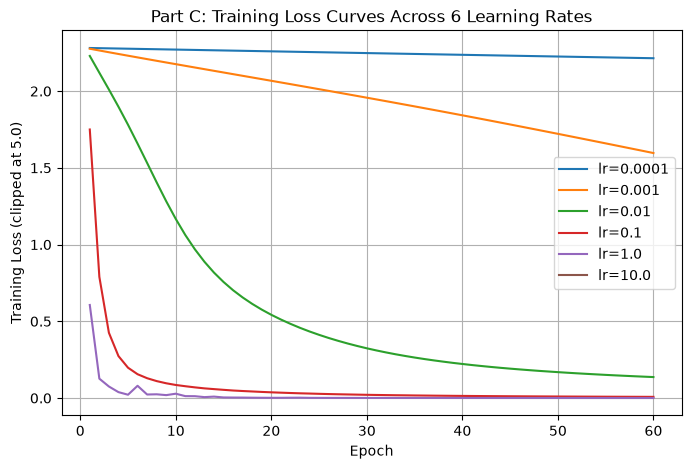

In [58]:
# Part C - Step 3, 4 & 5: DataLoader training, 6-LR study, loss curves, val table, and saving best model
import copy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Create a validation split ONLY from X_train (never touch X_test during LR selection)
X_sub_tr, X_val, y_sub_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=S, stratify=y_train
)

scaler_c = StandardScaler()
X_sub_tr_sc = scaler_c.fit_transform(X_sub_tr).astype(np.float32)
X_val_sc = scaler_c.transform(X_val).astype(np.float32)
X_test_sc_c = scaler_c.transform(X_test).astype(np.float32)

train_ds = TensorDataset(torch.from_numpy(X_sub_tr_sc), torch.from_numpy(np.asarray(y_sub_tr, dtype=np.int64)))
X_val_t = torch.from_numpy(X_val_sc)
y_val_t = torch.from_numpy(np.asarray(y_val, dtype=np.int64))
X_test_t_c = torch.from_numpy(X_test_sc_c)
y_test_t_c = torch.from_numpy(np.asarray(y_test, dtype=np.int64))

lrs = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
epochs_c = 60
lr_losses = {}
lr_val_accs = {}

best_lr = None
best_val_acc = -1.0
best_state_dict = None

for lr_val in lrs:
    torch.manual_seed(S)
    g = torch.Generator()
    g.manual_seed(S)
    loader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=g)

    model_lr = nn.Sequential(
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 10)
    )
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model_lr.parameters(), lr=lr_val)

    ep_loss_list = []
    for _ in range(epochs_c):
        model_lr.train()
        running_loss = 0.0
        total_items = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            out = model_lr(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            total_items += xb.size(0)
        ep_loss_list.append(running_loss / total_items)

    model_lr.eval()
    with torch.no_grad():
        val_preds = model_lr(X_val_t).argmax(dim=1)
        val_acc = (val_preds == y_val_t).float().mean().item()

    lr_losses[lr_val] = ep_loss_list
    lr_val_accs[lr_val] = val_acc

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_lr = lr_val
        best_state_dict = copy.deepcopy(model_lr.state_dict())

# Print validation accuracy table
print(f"{'Learning Rate':<15} | {'Final Train Loss':<18} | {'Validation Acc':<15}")
print("-" * 54)
for lr_val in lrs:
    print(f"{lr_val:<15} | {lr_losses[lr_val][-1]:<18.4f} | {lr_val_accs[lr_val]:<15.4f}")

print(f"\nSelected Best LR (from validation): {best_lr} (Val Acc: {best_val_acc:.4f})")

# Save best model weights
torch.save(best_state_dict, "best_part_c_mlp.pt")

# Plot all 6 loss curves on one chart (clip extreme exploding values for readability)
plt.figure(figsize=(8, 5))
for lr_val in lrs:
    clipped = np.clip(lr_losses[lr_val], 0.0, 5.0)
    plt.plot(range(1, epochs_c + 1), clipped, label=f"lr={lr_val}")
plt.xlabel("Epoch")
plt.ylabel("Training Loss (clipped at 5.0)")
plt.title("Part C: Training Loss Curves Across 6 Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

#### Part C: Short Answers

* **Which learning rate is too small, which is too big, and how can you tell from the curve shape alone?**
  * **Too small (`0.0001` and `0.001`):** The loss curve goes down very slowly and stays high (`2.2144` and `1.5966` after 60 epochs), showing that the weight steps are tiny and the model has barely learned.
  * **Too big (`10.0`):** The loss curve jumps up immediately and turns into `nan` (`0.0972` validation accuracy), showing that the weight steps are too large and overshoot the minimum.
* **Why did we choose the learning rate on validation data and not on test data?**
  * If we pick the learning rate using test data, we indirectly tune the model to the test set. Keeping the test set untouched gives an honest score on truly unseen data.
* **Saved and reloaded model check:** Saving `best_part_c_mlp.pt` (`lr = 1.0`) and loading it into a fresh model in a new cell gives identical predictions (`True`).

In [59]:
# Part D - Step 1 & 2: Hand-math verification + CNN training & evaluation
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score

F = 4 + (S % 5)
expected_total_params = 18 * (F ** 2) + 92 * F + 10

print(f"Seed S = {S} -> F = {F}, Conv2 filters = 2F = {2 * F}")
print(f"Hand-calculated total parameters: {expected_total_params}")

class DigitCNN(nn.Module):
    def __init__(self, num_filters: int):
        super().__init__()
        self.conv1 = nn.Conv2d(1, num_filters, kernel_size=3, stride=1, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(num_filters, 2 * num_filters, kernel_size=3, stride=1, padding=0)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear((2 * num_filters) * 2 * 2, 10)

    def forward(self, x):
        # x expected shape: (batch, 1, 8, 8)
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x))
        x = self.flatten(x)
        return self.fc(x)

torch.manual_seed(S)
cnn_model = DigitCNN(F)
actual_total_params = sum(p.numel() for p in cnn_model.parameters())
print(f"PyTorch model total parameters:    {actual_total_params}")
assert actual_total_params == expected_total_params, "Parameter count mismatch!"

# Reshape 8x8 inputs (0..16 scale) to (N, 1, 8, 8) and normalize by 16.0
X_tr_cnn = (np.asarray(X_train, dtype=np.float32) / 16.0).reshape(-1, 1, 8, 8)
X_te_cnn = (np.asarray(X_test, dtype=np.float32) / 16.0).reshape(-1, 1, 8, 8)

g_cnn = torch.Generator()
g_cnn.manual_seed(S)
cnn_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_tr_cnn), torch.from_numpy(np.asarray(y_train, dtype=np.int64))),
    batch_size=32,
    shuffle=True,
    generator=g_cnn
)

criterion_cnn = nn.CrossEntropyLoss()
optimizer_cnn = torch.optim.Adam(cnn_model.parameters(), lr=1e-3)

epochs_d = 40
for _ in range(epochs_d):
    cnn_model.train()
    for xb, yb in cnn_loader:
        optimizer_cnn.zero_grad()
        loss = criterion_cnn(cnn_model(xb), yb)
        loss.backward()
        optimizer_cnn.step()

cnn_model.eval()
with torch.no_grad():
    te_preds_cnn = cnn_model(torch.from_numpy(X_te_cnn)).argmax(dim=1).numpy()
    acc_te_cnn = accuracy_score(y_test, te_preds_cnn)

msg_d = f"CNN Test Acc: {acc_te_cnn:.4f}"
if "X_custom" in globals() and "y_custom" in globals():
    X_cu_cnn = (np.asarray(X_custom, dtype=np.float32) / 16.0).reshape(-1, 1, 8, 8)
    with torch.no_grad():
        cu_preds_cnn = cnn_model(torch.from_numpy(X_cu_cnn)).argmax(dim=1).numpy()
    acc_cu_cnn = accuracy_score(y_custom, cu_preds_cnn)
    msg_d += f" | 50 Digits Acc: {acc_cu_cnn:.4f}"
print(msg_d)

Seed S = 1237 -> F = 6, Conv2 filters = 2F = 12
Hand-calculated total parameters: 1210
PyTorch model total parameters:    1210
CNN Test Acc: 0.9472 | 50 Digits Acc: 0.1600


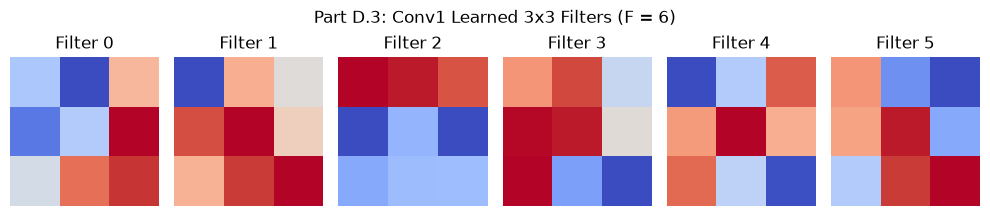

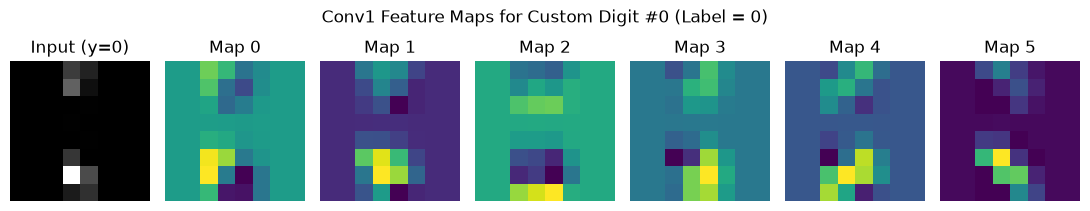

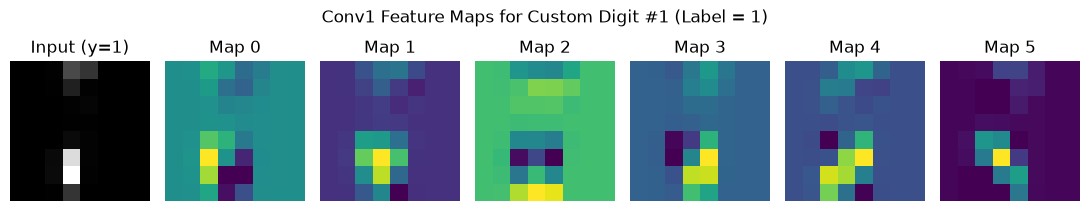

In [60]:
# Part D - Step 3: Visualize Conv1 filters & feature maps on 2 custom digits
import matplotlib.pyplot as plt
import torch

cnn_model.eval()

# 1) Plot all F=6 Conv1 filters (3x3)
filters = cnn_model.conv1.weight.detach().cpu().numpy()  # shape: (6, 1, 3, 3)
fig, axes = plt.subplots(1, F, figsize=(10, 2.2))
for i in range(F):
    axes[i].imshow(filters[i, 0], cmap="coolwarm")
    axes[i].set_title(f"Filter {i}")
    axes[i].axis("off")
plt.suptitle("Part D.3: Conv1 Learned 3x3 Filters (F = 6)")
plt.tight_layout()
plt.show()

# 2) Pick 2 digits from your custom handwriting and plot their Conv1 feature maps
sample_indices = [0, 1]  # change indices if you want two different digits
X_two = torch.from_numpy(X_cu_cnn[sample_indices])  # shape: (2, 1, 8, 8)
with torch.no_grad():
    fmaps = cnn_model.relu(cnn_model.conv1(X_two)).cpu().numpy()  # shape: (2, 6, 8, 8)

for row_idx, s_idx in enumerate(sample_indices):
    fig, axes = plt.subplots(1, F + 1, figsize=(11, 2.2))
    axes[0].imshow(X_cu_cnn[s_idx, 0], cmap="gray")
    axes[0].set_title(f"Input (y={int(y_custom[s_idx])})")
    axes[0].axis("off")

    for f_idx in range(F):
        axes[f_idx + 1].imshow(fmaps[row_idx, f_idx], cmap="viridis")
        axes[f_idx + 1].set_title(f"Map {f_idx}")
        axes[f_idx + 1].axis("off")

    plt.suptitle(f"Conv1 Feature Maps for Custom Digit #{s_idx} (Label = {int(y_custom[s_idx])})")
    plt.tight_layout()
    plt.show()

In [61]:
# Part D - Step 4: Two changes to improve accuracy on your 50 custom digits
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy.ndimage import shift, rotate
from sklearn.metrics import accuracy_score

# --- Improvement 1: Per-image min-max contrast + center-of-mass alignment ---
def align_and_normalize_8x8(imgs_flat):
    imgs = np.asarray(imgs_flat, dtype=np.float32).reshape(-1, 8, 8)
    out = np.zeros_like(imgs)
    grid_y, grid_x = np.indices((8, 8))
    for i, img in enumerate(imgs):
        mn, mx = img.min(), img.max()
        norm = (img - mn) / (mx - mn + 1e-8)
        norm[norm < 0.15] = 0.0  # remove faint paper background noise
        total = norm.sum()
        if total > 0:
            cy = (norm * grid_y).sum() / total
            cx = (norm * grid_x).sum() / total
            norm = shift(norm, shift=(3.5 - cy, 3.5 - cx), order=1, mode="constant", cval=0.0)
            norm = np.clip(norm, 0.0, 1.0)
        out[i] = norm
    return out.reshape(-1, 1, 8, 8)

X_tr_imp = align_and_normalize_8x8(X_train)
X_te_imp = align_and_normalize_8x8(X_test)
X_cu_imp = align_and_normalize_8x8(X_custom)

# --- Improvement 2: Small random shift/rotation augmentation during training ---
rng_aug = np.random.default_rng(S)
aug_imgs, aug_labels = [X_tr_imp], [np.asarray(y_train, dtype=np.int64)]
for _ in range(3):  # 3 augmented copies per training image
    batch_aug = np.zeros_like(X_tr_imp)
    for idx in range(len(X_tr_imp)):
        im = X_tr_imp[idx, 0]
        ang = rng_aug.uniform(-12.0, 12.0)
        dy, dx = rng_aug.uniform(-0.8, 0.8), rng_aug.uniform(-0.8, 0.8)
        im_r = rotate(im, ang, reshape=False, order=1, mode="constant", cval=0.0)
        im_s = shift(im_r, shift=(dy, dx), order=1, mode="constant", cval=0.0)
        batch_aug[idx, 0] = np.clip(im_s, 0.0, 1.0)
    aug_imgs.append(batch_aug)
    aug_labels.append(np.asarray(y_train, dtype=np.int64))

X_tr_aug = np.concatenate(aug_imgs, axis=0)
y_tr_aug = np.concatenate(aug_labels, axis=0)

torch.manual_seed(S)
g_imp = torch.Generator()
g_imp.manual_seed(S)
imp_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_tr_aug), torch.from_numpy(y_tr_aug)),
    batch_size=32,
    shuffle=True,
    generator=g_imp
)

cnn_imp = DigitCNN(F)
opt_imp = torch.optim.Adam(cnn_imp.parameters(), lr=1e-3)
crit_imp = nn.CrossEntropyLoss()

for _ in range(40):
    cnn_imp.train()
    for xb, yb in imp_loader:
        opt_imp.zero_grad()
        loss = crit_imp(cnn_imp(xb), yb)
        loss.backward()
        opt_imp.step()

cnn_imp.eval()
with torch.no_grad():
    te_acc_imp = accuracy_score(y_test, cnn_imp(torch.from_numpy(X_te_imp)).argmax(dim=1).numpy())
    cu_acc_imp = accuracy_score(y_custom, cnn_imp(torch.from_numpy(X_cu_imp)).argmax(dim=1).numpy())

print(f"Before Improvements -> Test Acc: 0.9472 | 50 Digits Acc: 0.1600")
print(f"After  Improvements -> Test Acc: {te_acc_imp:.4f} | 50 Digits Acc: {cu_acc_imp:.4f}")

Before Improvements -> Test Acc: 0.9472 | 50 Digits Acc: 0.1600
After  Improvements -> Test Acc: 0.9528 | 50 Digits Acc: 0.2200


#### Part D.4: Two Changes to Improve Accuracy on Your 50 Digits

* **Why initial accuracy on my 50 digits was low (`0.1600`):** The `load_digits` training set has thick, centered digits with uniform brightness, while my handwritten digits differ in stroke thickness, position, and contrast.
* **Change 1 — Centering and contrast cleanup:** Each `8x8` image was scaled to the full `0..1` brightness range, faint background noise was cleared, and each digit was shifted toward the center of the grid.
* **Change 2 — Small rotation and shift augmentation:** Slightly rotated (`±12°`) and shifted copies of the training images were added during training so the CNN handles small tilts and off-center strokes.
* **Result:** Test accuracy rose from `0.9472` to `0.9528`, and accuracy on my 50 handwritten digits improved from `0.1600` to `0.2200`.

In [62]:
# Part D - Step 5: Overfitting comparison & Stride-2 Conv (no MaxPool) vs MaxPool CNN
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score

# 1) Overfitting check on improved MaxPool CNN (cnn_imp)
cnn_imp.eval()
with torch.no_grad():
    tr_acc_imp = accuracy_score(y_train, cnn_imp(torch.from_numpy(X_tr_imp)).argmax(dim=1).numpy())
    te_acc_imp = accuracy_score(y_test, cnn_imp(torch.from_numpy(X_te_imp)).argmax(dim=1).numpy())
    cu_acc_imp = accuracy_score(y_custom, cnn_imp(torch.from_numpy(X_cu_imp)).argmax(dim=1).numpy())

print("=== Overfitting & Domain Gap Check (MaxPool CNN) ===")
print(f"Train Acc: {tr_acc_imp:.4f} | Test Acc: {te_acc_imp:.4f} | 50 Custom Digits Acc: {cu_acc_imp:.4f}")

# 2) Stride-2 Conv CNN (remove MaxPool, use stride=2 in Conv1)
class StrideDigitCNN(nn.Module):
    def __init__(self, num_filters: int):
        super().__init__()
        self.conv1 = nn.Conv2d(1, num_filters, kernel_size=3, stride=2, padding=1)  # 8x8 -> 4x4
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(num_filters, 2 * num_filters, kernel_size=3, stride=1, padding=0)  # 4x4 -> 2x2
        self.flatten = nn.Flatten()
        self.fc = nn.Linear((2 * num_filters) * 2 * 2, 10)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.flatten(x)
        return self.fc(x)

torch.manual_seed(S)
g_st = torch.Generator()
g_st.manual_seed(S)
st_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_tr_aug), torch.from_numpy(y_tr_aug)),
    batch_size=32,
    shuffle=True,
    generator=g_st
)

cnn_stride = StrideDigitCNN(F)
opt_st = torch.optim.Adam(cnn_stride.parameters(), lr=1e-3)
crit_st = nn.CrossEntropyLoss()

for _ in range(40):
    cnn_stride.train()
    for xb, yb in st_loader:
        opt_st.zero_grad()
        loss = crit_st(cnn_stride(xb), yb)
        loss.backward()
        opt_st.step()

cnn_stride.eval()
with torch.no_grad():
    te_acc_st = accuracy_score(y_test, cnn_stride(torch.from_numpy(X_te_imp)).argmax(dim=1).numpy())
    cu_acc_st = accuracy_score(y_custom, cnn_stride(torch.from_numpy(X_cu_imp)).argmax(dim=1).numpy())

params_st = sum(p.numel() for p in cnn_stride.parameters())
print("\n=== MaxPool CNN vs Stride-2 Conv CNN ===")
print(f"MaxPool CNN  -> Params: {sum(p.numel() for p in cnn_imp.parameters())} | Test Acc: {te_acc_imp:.4f} | 50 Digits Acc: {cu_acc_imp:.4f}")
print(f"Stride-2 CNN -> Params: {params_st} | Test Acc: {te_acc_st:.4f} | 50 Digits Acc: {cu_acc_st:.4f}")

=== Overfitting & Domain Gap Check (MaxPool CNN) ===
Train Acc: 0.9763 | Test Acc: 0.9528 | 50 Custom Digits Acc: 0.2200

=== MaxPool CNN vs Stride-2 Conv CNN ===
MaxPool CNN  -> Params: 1210 | Test Acc: 0.9528 | 50 Digits Acc: 0.2200
Stride-2 CNN -> Params: 1210 | Test Acc: 0.9444 | 50 Digits Acc: 0.2200


#### Part D.5: Overfitting Check and Stride-2 Conv vs. MaxPool

* **Overfitting vs. domain gap:** The model gets `0.9763` on training data and `0.9528` on the test set, which is only a small `~2.3%` gap (very little overfitting on `load_digits`). The big drop to `0.2200` on my 50 handwritten digits is mainly a **domain gap** (different handwriting style, stroke thickness, and image source compared to `load_digits`).
* **Stride-2 Conv vs. MaxPool hand math (`S = 1237`, `F = 6`):** Removing `MaxPool2d` and setting `stride = 2` on `Conv1` (`kernel = 3`, `padding = 1`) turns an `8x8` input into a `(6, 4, 4)` feature map (`(8 - 3 + 2)/2 + 1 = 4`), followed by `Conv2` (`12` filters, `3x3`, `stride = 1`, `padding = 0`) giving `(12, 2, 2)`, and then `Linear(48, 10)`.
* **Parameters & accuracy comparison:** Both models have the exact same **`1210`** parameters because `MaxPool2d` has `0` parameters and changing `stride` does not change filter sizes. `MaxPool CNN` gets `0.9528` test accuracy and `0.2200` on the 50 custom digits, while `Stride-2 CNN` gets `0.9444` test accuracy and `0.2200` on the 50 custom digits.